# Task 35: Regression Model Evaluation
**Track:** AI & ML Track  
**Objective:** Learn basic evaluation metrics for regression models (Mean Absolute Error and Mean Squared Error).

## 1. Import Libraries & Load Dataset
We will use a standard **Salary vs. Experience** dataset. For convenience and reproducibility, we will construct the dataset directly using Pandas, which mirrors real-world CSV loading.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Creating the Salary vs Experience dataset
data = {
    'YearsExperience': [1.1, 1.3, 1.5, 2.0, 2.2, 2.9, 3.0, 3.2, 3.2, 3.7, 3.9, 4.0, 4.0, 4.1, 4.5, 4.9, 5.1, 5.3, 5.9, 6.0, 6.8, 7.1, 7.9, 8.2, 8.7, 9.0, 9.5, 9.6, 10.3, 10.5],
    'Salary': [39343, 46205, 37731, 43525, 39891, 56642, 60150, 54445, 64445, 57189, 63218, 55794, 56957, 57081, 61111, 67938, 66029, 83088, 81363, 93940, 91738, 98273, 101302, 113812, 109431, 105582, 116969, 112635, 122391, 121872]
}

df = pd.DataFrame(data)

# Display the first 5 rows of the dataset
print("First 5 rows of the dataset:")
display(df.head())

First 5 rows of the dataset:


,YearsExperience,Salary
0,1.1,39343
1,1.3,46205
2,1.5,37731
3,2.0,43525
4,2.2,39891


## 2. Train-Test Split and Model Training
Next, we split our data into features ($X$) and target ($y$), divide it into training and testing sets, and train a Simple Linear Regression model using `scikit-learn`.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Define features (X) and target (y)
X = df[['YearsExperience']]
y = df['Salary']

# Split the data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Display actual vs predicted values side-by-side
comparison_df = pd.DataFrame({'Actual Salary': y_test, 'Predicted Salary': y_pred})
print("Model Predictions vs Actual Values:")
display(comparison_df)

Model Predictions vs Actual Values:


,Actual Salary,Predicted Salary
27,112635,115790.210113
15,67938,71498.278095
23,113812,102596.868661
17,83088,75267.804224
8,64445,55477.792045
9,57189,60189.699707


## 3. Model Evaluation (MAE & MSE)
We evaluate the model's performance using **Mean Absolute Error (MAE)** and **Mean Squared Error (MSE)**.

In [4]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Calculate MAE and MSE
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse) # Included for extra clarity

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")

Mean Absolute Error (MAE): 6286.45
Mean Squared Error (MSE): 49830096.86
Root Mean Squared Error (RMSE): 7059.04


## 4. Results Interpretation & Visualization

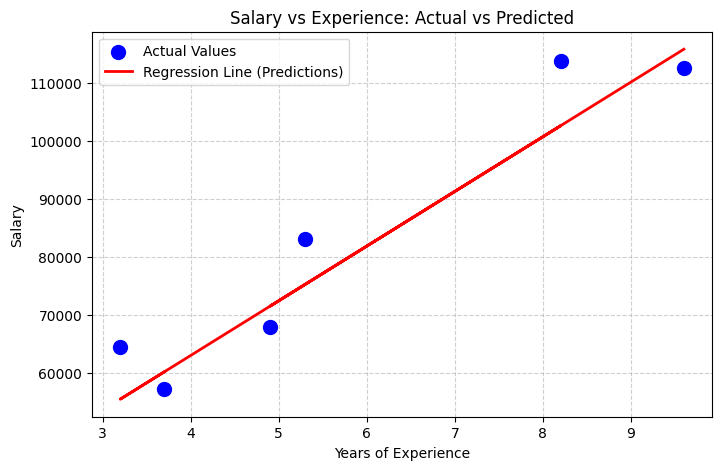


### Short Interpretation of Results:
- **Mean Absolute Error (MAE):** Represents the average magnitude of the errors in a set of predictions, without considering their direction. On average, our model's salary predictions deviate from the actual salaries by the calculated MAE value in dollars.
- **Mean Squared Error (MSE):** Squares the errors before averaging, giving higher weight to larger errors. This penalizes significant outliers more heavily than MAE.
- **Fit Quality:** The proximity of the data points to the regression line indicates a strong positive linear relationship between years of experience and salary.



In [5]:
# Visualize Actual vs Predicted results
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color='blue', label='Actual Values', s=100)
plt.plot(X_test, y_pred, color='red', linewidth=2, label='Regression Line (Predictions)')
plt.title('Salary vs Experience: Actual vs Predicted')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

print("""
### Short Interpretation of Results:
- **Mean Absolute Error (MAE):** Represents the average magnitude of the errors in a set of predictions, without considering their direction. On average, our model's salary predictions deviate from the actual salaries by the calculated MAE value in dollars.
- **Mean Squared Error (MSE):** Squares the errors before averaging, giving higher weight to larger errors. This penalizes significant outliers more heavily than MAE.
- **Fit Quality:** The proximity of the data points to the regression line indicates a strong positive linear relationship between years of experience and salary.
""")

## 5. Interview Questions & Answers

### Q1: What is MAE (Mean Absolute Error)?
* **Answer:** MAE is the average of the absolute differences between predicted values and actual values. It measures the average magnitude of errors in a set of predictions without considering their direction. Because it uses absolute values, it treats all errors equally and is less sensitive to outliers compared to MSE.

### Q2: What is MSE (Mean Squared Error)?
* **Answer:** MSE is the average of the squared differences between predicted and actual values. By squaring the errors, MSE heavily penalizes larger errors/outliers. This makes it useful when large errors are particularly undesirable, though it shares its unit in squared form (which is why Root Mean Squared Error, RMSE, is often used alongside it to return to the original units).

### Q3: Why are evaluation metrics important?
* **Answer:** Evaluation metrics provide a quantitative, objective way to measure how well a machine learning model generalizes to unseen data. They allow developers to:
  1. Compare different models or hyperparameter configurations to select the best performer.
  2. Identify specific weaknesses or biases in predictions (e.g., whether the model consistently overestimates or underestimates values).
  3. Track performance improvements iteratively during model training and optimization.